In [1]:
import numpy as np

data = np.genfromtxt(
    "../data/ETP_4_New_Data_Accidents.csv",
    delimiter=",",
    dtype=None,
    encoding="utf-8",
    names=True
)

clean_data = np.unique(data)

print("Clean records:", len(clean_data))
print("Columns:", clean_data.dtype.names)

Clean records: 4053
Columns: ('Date', 'Day_of_Week', 'Time_of_Accident', 'Accident_Location_A', 'Accident_Location_A_Chainage_km', 'Accident_Location_A_Chainage_km_RoadSide', 'Accident_Severity_C', 'Causes_D', 'Road_Feature_E', 'Road_Condition_F', 'Weather_Conditions_H', 'Vehicle_Type_Involved_J_V1', 'Vehicle_Type_Involved_J_V2')


In [2]:
severity = clean_data["Accident_Severity_C"]

years = np.array([
    int(date.split("/")[2])
    for date in clean_data["Date"]
])

months = np.array([
    int(date.split("/")[1])
    for date in clean_data["Date"]
])

hours = np.array([
    int(time.split(":")[0])
    for time in clean_data["Time_of_Accident"]
])

day_of_week = clean_data["Day_of_Week"]

chainage = clean_data["Accident_Location_A_Chainage_km"]

print("Arrays prepared.")

Arrays prepared.


In [3]:
year_values, year_counts = np.unique(
    years,
    return_counts=True
)

for year, count in zip(year_values, year_counts):
    print(f"{year}: {count}")

2003: 1
2013: 113
2014: 274
2015: 734
2016: 616
2017: 1242
2018: 268
2022: 594
2023: 211


In [4]:
month_values, month_counts = np.unique(
    months,
    return_counts=True
)

print("Monthly accident distribution:\n")

for month, count in zip(month_values, month_counts):
    print(f"Month {month:02d}: {count}")

Monthly accident distribution:

Month 01: 322
Month 02: 271
Month 03: 310
Month 04: 336
Month 05: 366
Month 06: 481
Month 07: 427
Month 08: 292
Month 09: 367
Month 10: 309
Month 11: 281
Month 12: 291


In [5]:
monthly_percentage = (
    month_counts / len(clean_data)
) * 100

month_names = np.array([
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
])

print("Monthly accident share:\n")

for month, count, percentage in zip(
    month_names,
    month_counts,
    monthly_percentage
):
    print(
        f"{month}: {count} accidents "
        f"({percentage:.2f}%)"
    )

Monthly accident share:

Jan: 322 accidents (7.94%)
Feb: 271 accidents (6.69%)
Mar: 310 accidents (7.65%)
Apr: 336 accidents (8.29%)
May: 366 accidents (9.03%)
Jun: 481 accidents (11.87%)
Jul: 427 accidents (10.54%)
Aug: 292 accidents (7.20%)
Sep: 367 accidents (9.06%)
Oct: 309 accidents (7.62%)
Nov: 281 accidents (6.93%)
Dec: 291 accidents (7.18%)


In [6]:
hour_values, hour_counts = np.unique(
    hours,
    return_counts=True
)

print("Hourly accident distribution:\n")

for hour, count in zip(hour_values, hour_counts):
    print(f"{hour:02d}:00 → {count}")

Hourly accident distribution:

00:00 → 160
01:00 → 162
02:00 → 112
03:00 → 116
04:00 → 133
05:00 → 177
06:00 → 146
07:00 → 162
08:00 → 156
09:00 → 164
10:00 → 190
11:00 → 192
12:00 → 189
13:00 → 156
14:00 → 160
15:00 → 160
16:00 → 213
17:00 → 184
18:00 → 179
19:00 → 215
20:00 → 194
21:00 → 168
22:00 → 176
23:00 → 189


In [7]:
day_mask = (hours >= 6) & (hours < 18)
night_mask = ~day_mask

day_count = np.sum(day_mask)
night_count = np.sum(night_mask)

day_percentage = (day_count / len(clean_data)) * 100
night_percentage = (night_count / len(clean_data)) * 100

print(f"Daytime   : {day_count} ({day_percentage:.2f}%)")
print(f"Nighttime : {night_count} ({night_percentage:.2f}%)")

Daytime   : 2072 (51.12%)
Nighttime : 1981 (48.88%)


In [8]:
day_severity = severity[day_mask]
night_severity = severity[night_mask]

day_sev_values, day_sev_counts = np.unique(
    day_severity,
    return_counts=True
)

night_sev_values, night_sev_counts = np.unique(
    night_severity,
    return_counts=True
)

print("Daytime severity:\n")

for sev, count in zip(day_sev_values, day_sev_counts):
    percentage = (count / day_count) * 100
    print(
        f"Severity {sev}: "
        f"{count} ({percentage:.2f}%)"
    )

print("\nNighttime severity:\n")

for sev, count in zip(night_sev_values, night_sev_counts):
    percentage = (count / night_count) * 100
    print(
        f"Severity {sev}: "
        f"{count} ({percentage:.2f}%)"
    )

Daytime severity:

Severity 1: 172 (8.30%)
Severity 2: 699 (33.74%)
Severity 3: 830 (40.06%)
Severity 4: 371 (17.91%)

Nighttime severity:

Severity 1: 180 (9.09%)
Severity 2: 751 (37.91%)
Severity 3: 712 (35.94%)
Severity 4: 338 (17.06%)


In [9]:
day_mean_severity = np.mean(day_severity)
night_mean_severity = np.mean(night_severity)

overall_mean_severity = np.mean(severity)

print(f"Overall mean severity : {overall_mean_severity:.3f}")
print(f"Daytime mean severity : {day_mean_severity:.3f}")
print(f"Nighttime mean severity: {night_mean_severity:.3f}")

Overall mean severity : 2.643
Daytime mean severity : 2.676
Nighttime mean severity: 2.610


In [10]:
cause_values, cause_counts = np.unique(
    clean_data["Causes_D"],
    return_counts=True
)

cause_percentage = (
    cause_counts / len(clean_data)
) * 100

print("Accident cause distribution:\n")

for cause, count, percentage in zip(
    cause_values,
    cause_counts,
    cause_percentage
):
    print(
        f"Cause {cause}: "
        f"{count} ({percentage:.2f}%)"
    )

Accident cause distribution:

Cause 1: 237 (5.85%)
Cause 2: 1905 (47.00%)
Cause 3: 1477 (36.44%)
Cause 4: 343 (8.46%)
Cause 5: 88 (2.17%)
Cause 6: 1 (0.02%)
Cause 8: 2 (0.05%)


In [11]:
causes = clean_data["Causes_D"]

cause_severity_matrix = np.zeros(
    (len(cause_values), 4),
    dtype=int
)

for i, cause in enumerate(cause_values):
    cause_severities = severity[causes == cause]

    values, counts = np.unique(
        cause_severities,
        return_counts=True
    )

    for value, count in zip(values, counts):
        cause_severity_matrix[i, int(value) - 1] = count

print("Rows = causes")
print("Columns = severity 1, 2, 3, 4\n")
print(cause_severity_matrix)

Rows = causes
Columns = severity 1, 2, 3, 4

[[ 22  89 107  19]
 [195 712 720 278]
 [ 92 528 592 265]
 [ 42 109 108  84]
 [  1  11  14  62]
 [  0   0   1   0]
 [  0   1   0   1]]


In [12]:
cause_mean_severity = np.array([
    severity[causes == cause].mean()
    for cause in cause_values
])

print("Mean severity by cause:\n")

for cause, mean_value, count in zip(
    cause_values,
    cause_mean_severity,
    cause_counts
):
    print(
        f"Cause {cause}: "
        f"Mean Severity = {mean_value:.3f}"
        f" | Accidents = {count}"
    )

Mean severity by cause:

Cause 1: Mean Severity = 2.519 | Accidents = 237
Cause 2: Mean Severity = 2.567 | Accidents = 1905
Cause 3: Mean Severity = 2.697 | Accidents = 1477
Cause 4: Mean Severity = 2.682 | Accidents = 343
Cause 5: Mean Severity = 3.557 | Accidents = 88
Cause 6: Mean Severity = 3.000 | Accidents = 1
Cause 8: Mean Severity = 3.000 | Accidents = 2


In [13]:
road_condition = clean_data["Road_Condition_F"]

condition_values, condition_counts = np.unique(
    road_condition,
    return_counts=True
)

condition_percentage = (
    condition_counts / len(clean_data)
) * 100

print("Road condition distribution:\n")

for condition, count, percentage in zip(
    condition_values,
    condition_counts,
    condition_percentage
):
    print(
        f"Condition {condition}: "
        f"{count} ({percentage:.2f}%)"
    )

Road condition distribution:

Condition 1: 3394 (83.74%)
Condition 2: 286 (7.06%)
Condition 3: 72 (1.78%)
Condition 4: 245 (6.04%)
Condition 5: 18 (0.44%)
Condition 6: 15 (0.37%)
Condition 7: 6 (0.15%)
Condition 8: 17 (0.42%)


In [14]:
condition_mean_severity = np.array([
    severity[road_condition == condition].mean()
    for condition in condition_values
])

print("\nMean severity by road condition:\n")

for condition, mean_value, count in zip(
    condition_values,
    condition_mean_severity,
    condition_counts
):
    print(
        f"Condition {condition}: "
        f"Mean Severity = {mean_value:.3f}"
        f" | Accidents = {count}"
    )


Mean severity by road condition:

Condition 1: Mean Severity = 2.608 | Accidents = 3394
Condition 2: Mean Severity = 2.846 | Accidents = 286
Condition 3: Mean Severity = 2.833 | Accidents = 72
Condition 4: Mean Severity = 2.747 | Accidents = 245
Condition 5: Mean Severity = 2.889 | Accidents = 18
Condition 6: Mean Severity = 3.333 | Accidents = 15
Condition 7: Mean Severity = 3.167 | Accidents = 6
Condition 8: Mean Severity = 3.000 | Accidents = 17


In [15]:
weather = clean_data["Weather_Conditions_H"]

weather_values, weather_counts = np.unique(
    weather,
    return_counts=True
)

weather_percentage = (
    weather_counts / len(clean_data)
) * 100

print("Weather condition distribution:\n")

for condition, count, percentage in zip(
    weather_values,
    weather_counts,
    weather_percentage
):
    print(
        f"Weather {condition}: "
        f"{count} ({percentage:.2f}%)"
    )

Weather condition distribution:

Weather 1: 2667 (65.80%)
Weather 2: 597 (14.73%)
Weather 3: 230 (5.67%)
Weather 4: 91 (2.25%)
Weather 5: 44 (1.09%)
Weather 6: 1 (0.02%)
Weather 7: 7 (0.17%)
Weather 8: 48 (1.18%)
Weather 9: 95 (2.34%)
Weather 10: 216 (5.33%)
Weather 11: 33 (0.81%)
Weather 12: 24 (0.59%)


In [16]:
weather_mean_severity = np.array([
    severity[weather == condition].mean()
    for condition in weather_values
])

print("\nMean severity by weather condition:\n")

for condition, mean_value, count in zip(
    weather_values,
    weather_mean_severity,
    weather_counts
):
    print(
        f"Weather {condition}: "
        f"Mean Severity = {mean_value:.3f}"
        f" | Accidents = {count}"
    )


Mean severity by weather condition:

Weather 1: Mean Severity = 2.607 | Accidents = 2667
Weather 2: Mean Severity = 2.660 | Accidents = 597
Weather 3: Mean Severity = 2.704 | Accidents = 230
Weather 4: Mean Severity = 2.484 | Accidents = 91
Weather 5: Mean Severity = 2.841 | Accidents = 44
Weather 6: Mean Severity = 3.000 | Accidents = 1
Weather 7: Mean Severity = 3.429 | Accidents = 7
Weather 8: Mean Severity = 3.000 | Accidents = 48
Weather 9: Mean Severity = 2.968 | Accidents = 95
Weather 10: Mean Severity = 2.704 | Accidents = 216
Weather 11: Mean Severity = 2.576 | Accidents = 33
Weather 12: Mean Severity = 3.208 | Accidents = 24


In [17]:
vehicle_v1 = clean_data["Vehicle_Type_Involved_J_V1"]

vehicle_values, vehicle_counts = np.unique(
    vehicle_v1,
    return_counts=True
)

vehicle_percentage = (
    vehicle_counts / len(clean_data)
) * 100

print("Primary vehicle distribution:\n")

for vehicle, count, percentage in zip(
    vehicle_values,
    vehicle_counts,
    vehicle_percentage
):
    print(
        f"Vehicle {vehicle}: "
        f"{count} ({percentage:.2f}%)"
    )

Primary vehicle distribution:

Vehicle 1: 926 (22.85%)
Vehicle 2: 22 (0.54%)
Vehicle 3: 106 (2.62%)
Vehicle 4: 10 (0.25%)
Vehicle 5: 1071 (26.42%)
Vehicle 6: 1096 (27.04%)
Vehicle 7: 54 (1.33%)
Vehicle 8: 73 (1.80%)
Vehicle 9: 152 (3.75%)
Vehicle 10: 46 (1.13%)
Vehicle 11: 361 (8.91%)
Vehicle 12: 9 (0.22%)
Vehicle 14: 82 (2.02%)
Vehicle 15: 45 (1.11%)


In [18]:
vehicle_v2 = clean_data["Vehicle_Type_Involved_J_V2"]

single_vehicle_mask = vehicle_v2 == -1
multi_vehicle_mask = vehicle_v2 != -1

single_count = np.sum(single_vehicle_mask)
multi_count = np.sum(multi_vehicle_mask)

single_percentage = (
    single_count / len(clean_data)
) * 100

multi_percentage = (
    multi_count / len(clean_data)
) * 100

print(
    f"Single-vehicle records: "
    f"{single_count} ({single_percentage:.2f}%)"
)

print(
    f"Multi-vehicle records: "
    f"{multi_count} ({multi_percentage:.2f}%)"
)

Single-vehicle records: 3075 (75.87%)
Multi-vehicle records: 978 (24.13%)


In [19]:
single_mean_severity = np.mean(
    severity[single_vehicle_mask]
)

multi_mean_severity = np.mean(
    severity[multi_vehicle_mask]
)

print(
    f"Single-vehicle mean severity: "
    f"{single_mean_severity:.3f}"
)

print(
    f"Multi-vehicle mean severity: "
    f"{multi_mean_severity:.3f}"
)

Single-vehicle mean severity: 2.677
Multi-vehicle mean severity: 2.537


In [20]:
single_severity = severity[single_vehicle_mask]
multi_severity = severity[multi_vehicle_mask]

single_values, single_counts = np.unique(
    single_severity,
    return_counts=True
)

multi_values, multi_counts = np.unique(
    multi_severity,
    return_counts=True
)

print("Single-vehicle severity:\n")

for sev, count in zip(single_values, single_counts):
    percentage = (count / single_count) * 100
    print(
        f"Severity {sev}: "
        f"{count} ({percentage:.2f}%)"
    )

print("\nMulti-vehicle severity:\n")

for sev, count in zip(multi_values, multi_counts):
    percentage = (count / multi_count) * 100
    print(
        f"Severity {sev}: "
        f"{count} ({percentage:.2f}%)"
    )

Single-vehicle severity:

Severity 1: 231 (7.51%)
Severity 2: 1102 (35.84%)
Severity 3: 1170 (38.05%)
Severity 4: 572 (18.60%)

Multi-vehicle severity:

Severity 1: 121 (12.37%)
Severity 2: 348 (35.58%)
Severity 3: 372 (38.04%)
Severity 4: 137 (14.01%)


In [21]:
segments = np.floor(chainage / 10).astype(int)

segment_values, segment_counts = np.unique(
    segments,
    return_counts=True
)

segment_mean_severity = np.array([
    severity[segments == segment].mean()
    for segment in segment_values
])

location_ranking = np.argsort(
    segment_counts
)[::-1]

print("Top 15 segments by recorded accident count:\n")

for rank, index in enumerate(
    location_ranking[:15],
    start=1
):
    start_km = segment_values[index] * 10
    end_km = start_km + 10

    print(
        f"{rank}. {start_km:.0f}-{end_km:.0f} km"
        f" | Accidents: {segment_counts[index]}"
        f" | Mean Severity: {segment_mean_severity[index]:.3f}"
    )

Top 15 segments by recorded accident count:

1. 490-500 km | Accidents: 467 | Mean Severity: 2.411
2. 500-510 km | Accidents: 234 | Mean Severity: 2.568
3. 220-230 km | Accidents: 202 | Mean Severity: 2.728
4. 180-190 km | Accidents: 197 | Mean Severity: 2.701
5. 480-490 km | Accidents: 181 | Mean Severity: 2.448
6. 170-180 km | Accidents: 177 | Mean Severity: 2.689
7. 230-240 km | Accidents: 173 | Mean Severity: 2.711
8. 210-220 km | Accidents: 172 | Mean Severity: 2.814
9. 430-440 km | Accidents: 163 | Mean Severity: 2.509
10. 240-250 km | Accidents: 146 | Mean Severity: 2.966
11. 420-430 km | Accidents: 140 | Mean Severity: 2.414
12. 450-460 km | Accidents: 129 | Mean Severity: 2.659
13. 200-210 km | Accidents: 122 | Mean Severity: 2.918
14. 460-470 km | Accidents: 122 | Mean Severity: 2.467
15. 190-200 km | Accidents: 121 | Mean Severity: 2.934


In [22]:
accident_threshold = np.percentile(
    segment_counts,
    75
)

severity_threshold = np.percentile(
    segment_mean_severity,
    75
)

high_volume_mask = (
    segment_counts >= accident_threshold
)

high_severity_mask = (
    segment_mean_severity >= severity_threshold
)

combined_mask = (
    high_volume_mask
    & high_severity_mask
)

print(
    "75th percentile accident count:",
    accident_threshold
)

print(
    "75th percentile mean severity:",
    severity_threshold
)

print(
    "\nSegments meeting BOTH conditions:",
    np.sum(combined_mask)
)

75th percentile accident count: 121.0
75th percentile mean severity: 2.8421052631578947

Segments meeting BOTH conditions: 3


In [23]:
combined_indices = np.where(combined_mask)[0]

combined_indices = combined_indices[
    np.argsort(
        segment_counts[combined_indices]
    )[::-1]
]

print("\nHigh-volume + high-severity segments:\n")

for index in combined_indices:
    start_km = segment_values[index] * 10
    end_km = start_km + 10

    print(
        f"{start_km:.0f}-{end_km:.0f} km"
        f" | Accidents: {segment_counts[index]}"
        f" | Mean Severity: {segment_mean_severity[index]:.3f}"
    )


High-volume + high-severity segments:

240-250 km | Accidents: 146 | Mean Severity: 2.966
200-210 km | Accidents: 122 | Mean Severity: 2.918
190-200 km | Accidents: 121 | Mean Severity: 2.934


In [25]:
# Recreate the final risk components from the cleaned data

# Spatial concentration
concentration_score = (
    (segment_counts - segment_counts.min())
    / (segment_counts.max() - segment_counts.min())
)

# Severity
severity_score = (
    (segment_mean_severity - segment_mean_severity.min())
    / (segment_mean_severity.max() - segment_mean_severity.min())
)

# Severity reliability
k = 10

severity_reliability = (
    segment_counts / (segment_counts + k)
)

adjusted_severity_score = (
    severity_score * severity_reliability
)

# Temporal concentration
hour_distribution = np.zeros(
    (len(segment_values), 24)
)

for i, segment in enumerate(segment_values):
    segment_hours = hours[segments == segment]

    values, counts = np.unique(
        segment_hours,
        return_counts=True
    )

    hour_distribution[i, values] = counts

hour_probabilities = (
    hour_distribution
    / hour_distribution.sum(
        axis=1,
        keepdims=True
    )
)

safe_probabilities = np.where(
    hour_probabilities > 0,
    hour_probabilities,
    1
)

hour_entropy = -np.sum(
    hour_probabilities
    * np.log2(safe_probabilities),
    axis=1
)

min_entropy = hour_entropy.min()
max_entropy = hour_entropy.max()

temporal_concentration_score = (
    1
    - (
        (hour_entropy - min_entropy)
        / (max_entropy - min_entropy)
    )
)

temporal_reliability = (
    segment_counts
    / (segment_counts + k)
)

adjusted_temporal_score = (
    temporal_concentration_score
    * temporal_reliability
)

# Final MargGanit indicator
risk_indicator_final = (
    concentration_score
    + adjusted_severity_score
    + adjusted_temporal_score
) / 3

# Rank segments
risk_ranking = np.argsort(
    risk_indicator_final
)[::-1]

print("Top 10 MargGanit segments:\n")

for rank, index in enumerate(
    risk_ranking[:10],
    start=1
):
    start_km = segment_values[index] * 10
    end_km = start_km + 10

    print(
        f"{rank}. {start_km:.0f}-{end_km:.0f} km"
        f" | Risk: {risk_indicator_final[index]:.3f}"
        f" | Accidents: {segment_counts[index]}"
        f" | Mean Severity: {segment_mean_severity[index]:.3f}"
    )

Top 10 MargGanit segments:

1. 490-500 km | Risk: 0.509 | Accidents: 467 | Mean Severity: 2.411
2. 220-230 km | Risk: 0.374 | Accidents: 202 | Mean Severity: 2.728
3. 240-250 km | Risk: 0.373 | Accidents: 146 | Mean Severity: 2.966
4. 500-510 km | Risk: 0.370 | Accidents: 234 | Mean Severity: 2.568
5. 180-190 km | Risk: 0.369 | Accidents: 197 | Mean Severity: 2.701
6. 210-220 km | Risk: 0.366 | Accidents: 172 | Mean Severity: 2.814
7. 190-200 km | Risk: 0.357 | Accidents: 121 | Mean Severity: 2.934
8. 170-180 km | Risk: 0.352 | Accidents: 177 | Mean Severity: 2.689
9. 230-240 km | Risk: 0.349 | Accidents: 173 | Mean Severity: 2.711
10. 200-210 km | Risk: 0.346 | Accidents: 122 | Mean Severity: 2.918


In [ ]:
# 10. Visual Analysis


In [28]:
import matplotlib.pyplot as plt

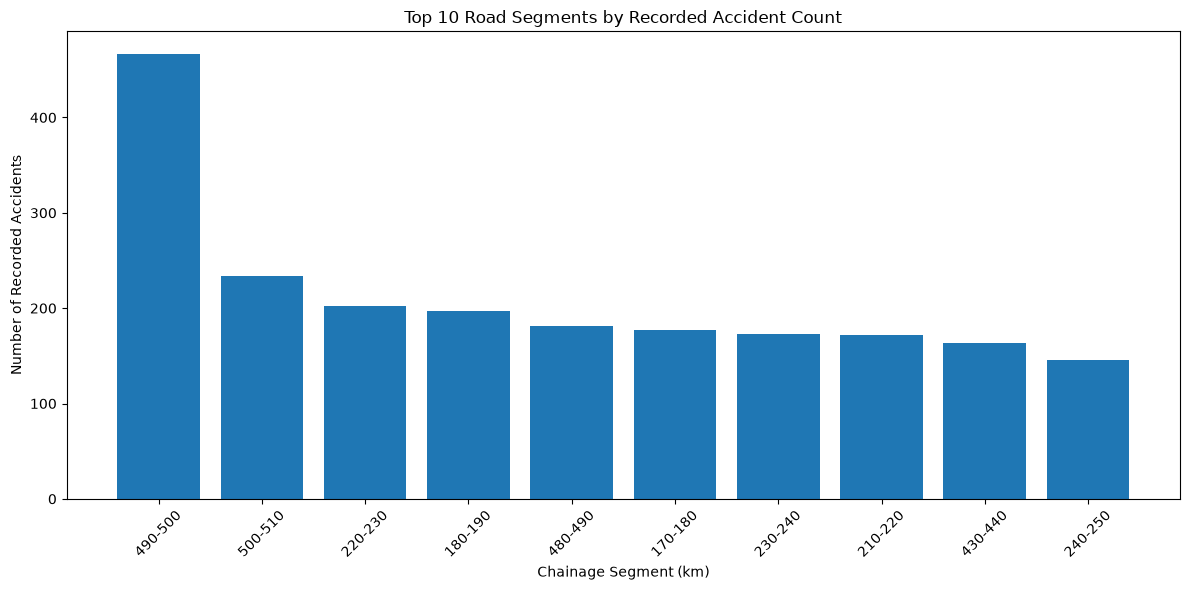

In [30]:
# Top 10 segments by recorded accident count

top_count_indices = np.argsort(segment_counts)[::-1][:10]

top_segments = segment_values[top_count_indices]
top_counts = segment_counts[top_count_indices]

labels = [
    f"{segment * 10:.0f}-{segment * 10 + 10:.0f}"
    for segment in top_segments
]

plt.figure(figsize=(12, 6))

plt.bar(labels, top_counts)

plt.title("Top 10 Road Segments by Recorded Accident Count")
plt.xlabel("Chainage Segment (km)")
plt.ylabel("Number of Recorded Accidents")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

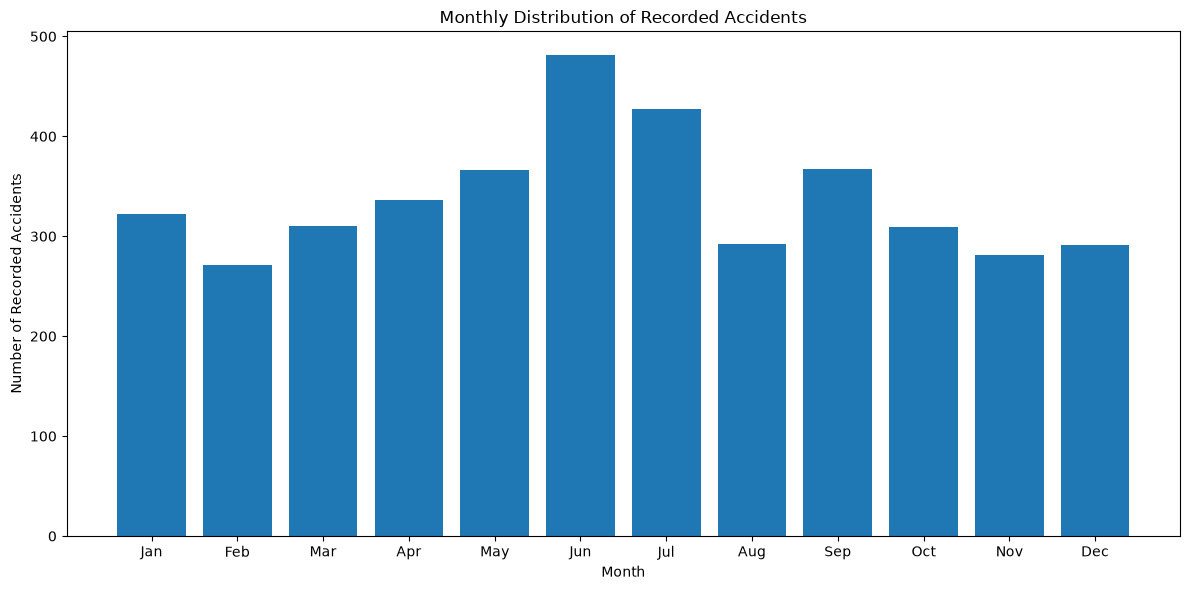

In [31]:
# Monthly recorded accident distribution

monthly_counts = np.bincount(
    months,
    minlength=13
)[1:]

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

plt.bar(month_labels, monthly_counts)

plt.title("Monthly Distribution of Recorded Accidents")
plt.xlabel("Month")
plt.ylabel("Number of Recorded Accidents")

plt.tight_layout()
plt.show()

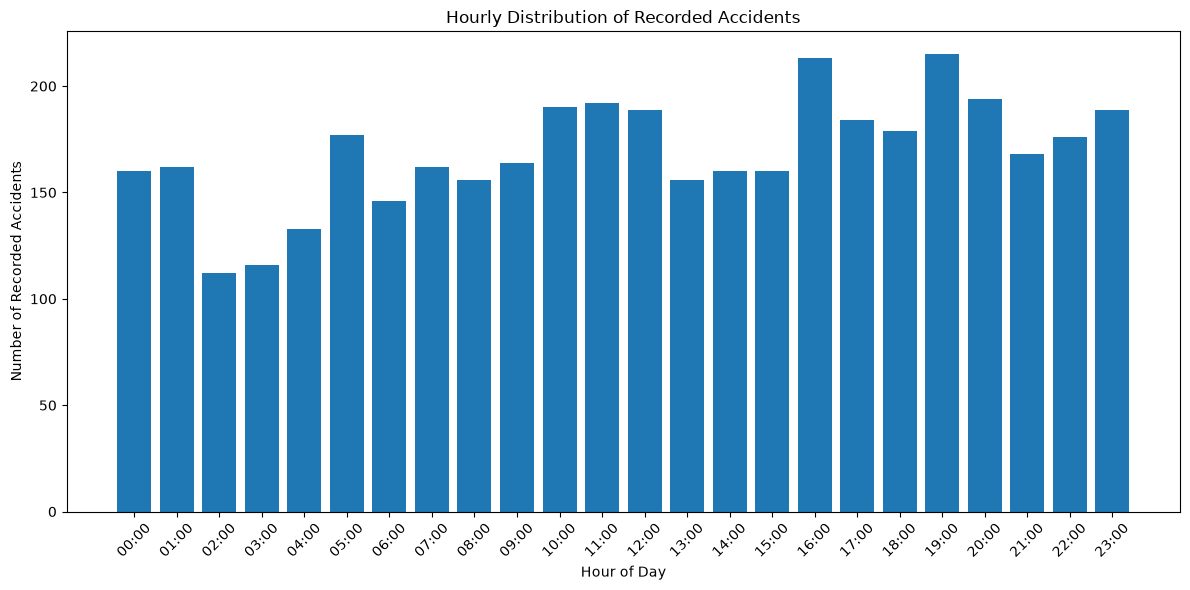

In [32]:
# Hourly recorded accident distribution

hourly_counts = np.bincount(
    hours,
    minlength=24
)

hour_labels = [f"{h:02d}:00" for h in range(24)]

plt.figure(figsize=(12, 6))

plt.bar(hour_labels, hourly_counts)

plt.title("Hourly Distribution of Recorded Accidents")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Recorded Accidents")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

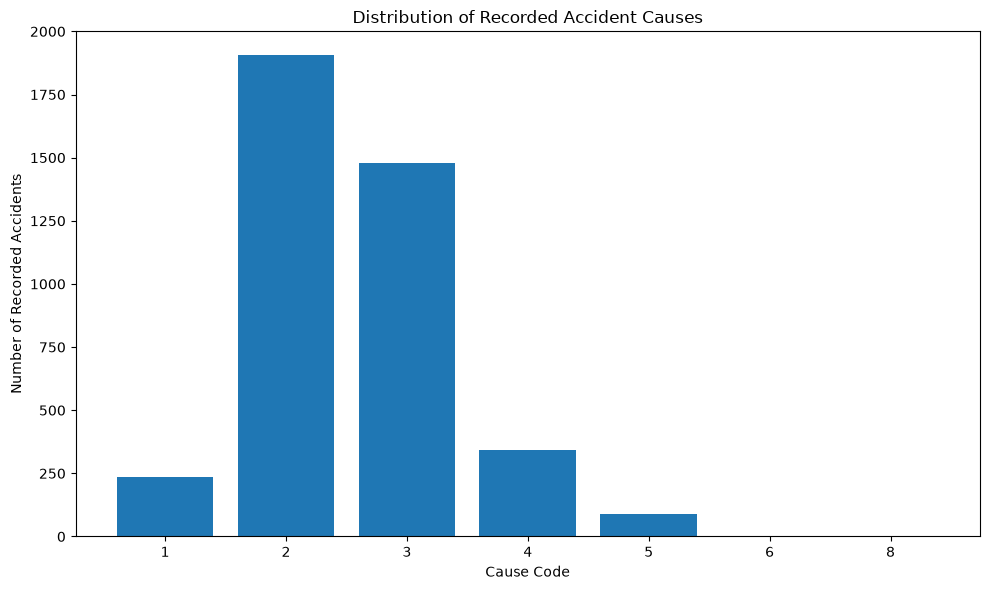

In [33]:
# Cause distribution

cause_values, cause_counts = np.unique(
    clean_data["Causes_D"],
    return_counts=True
)

plt.figure(figsize=(10, 6))

plt.bar(
    [str(cause) for cause in cause_values],
    cause_counts
)

plt.title("Distribution of Recorded Accident Causes")
plt.xlabel("Cause Code")
plt.ylabel("Number of Recorded Accidents")

plt.tight_layout()
plt.show()

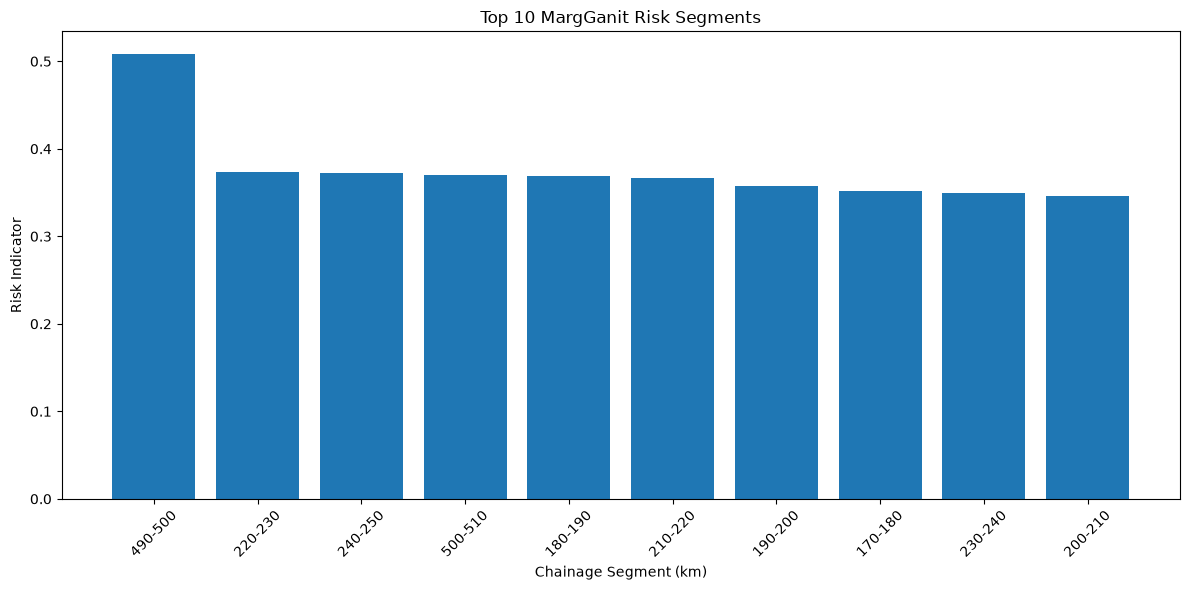

In [34]:
# Top 10 MargGanit risk segments

top_risk_indices = risk_ranking[:10]

risk_labels = [
    f"{segment_values[i] * 10:.0f}-{segment_values[i] * 10 + 10:.0f}"
    for i in top_risk_indices
]

risk_values = risk_indicator_final[top_risk_indices]

plt.figure(figsize=(12, 6))

plt.bar(risk_labels, risk_values)

plt.title("Top 10 MargGanit Risk Segments")
plt.xlabel("Chainage Segment (km)")
plt.ylabel("Risk Indicator")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

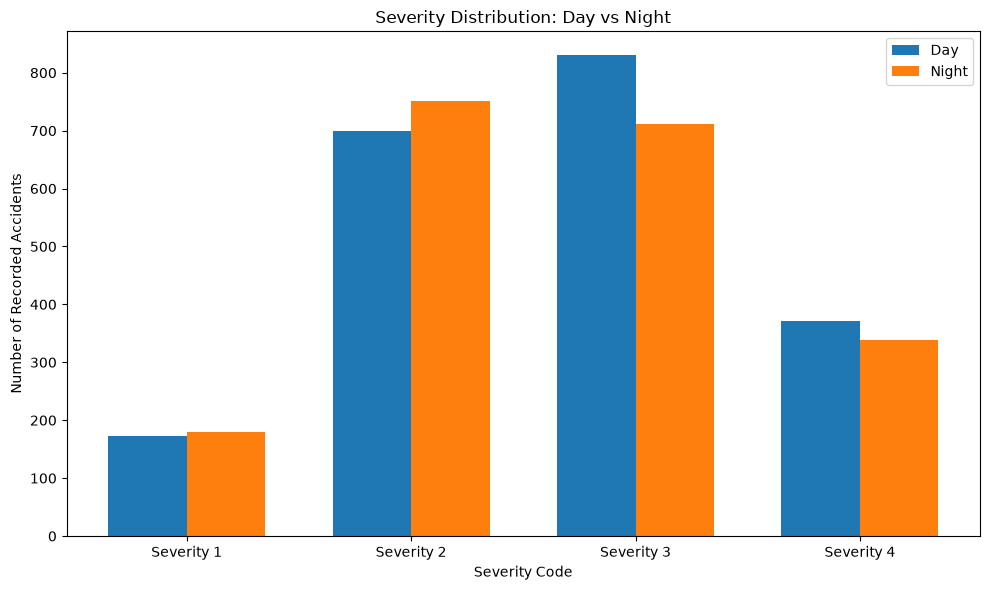

In [35]:
# Day vs Night severity distribution

day_mask = (hours >= 6) & (hours < 18)
night_mask = ~day_mask

day_severity_counts = np.bincount(
    severity[day_mask],
    minlength=5
)[1:]

night_severity_counts = np.bincount(
    severity[night_mask],
    minlength=5
)[1:]

severity_labels = [
    "Severity 1",
    "Severity 2",
    "Severity 3",
    "Severity 4"
]

x = np.arange(len(severity_labels))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    day_severity_counts,
    width,
    label="Day"
)

plt.bar(
    x + width / 2,
    night_severity_counts,
    width,
    label="Night"
)

plt.title("Severity Distribution: Day vs Night")
plt.xlabel("Severity Code")
plt.ylabel("Number of Recorded Accidents")

plt.xticks(x, severity_labels)
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
# 11. Final Analysis Summary and Limitations

print("MARGGANIT — FINAL ANALYSIS SUMMARY")
print("=" * 50)

print(f"Unique accident records analyzed: {len(clean_data)}")
print(f"Road segments analyzed: {len(segment_values)}")

print("\nTop Risk Segment:")
top_index = risk_ranking[0]

print(
    f"{segment_values[top_index] * 10:.0f}-"
    f"{segment_values[top_index] * 10 + 10:.0f} km"
)

print(f"Risk Indicator: {risk_indicator_final[top_index]:.3f}")
print(f"Recorded Accidents: {segment_counts[top_index]}")
print(
    f"Mean Severity: "
    f"{segment_mean_severity[top_index]:.3f}"
)

print("\nKey Analytical Findings:")
print("- Accident concentration is highly uneven across road segments.")
print("- The 490-500 km segment has the highest recorded accident concentration.")
print("- Several lower-volume segments show higher mean severity.")
print("- Accident occurrence varies across months and hours.")
print("- Cause codes 2 and 3 dominate the recorded dataset.")
print("- Day and night contain similar overall accident volumes.")

print("\nImportant Limitations:")
print("- Analysis uses recorded accident counts, not exposure-adjusted accident rates.")
print("- The dataset contains gaps between recorded years.")
print("- Numeric cause, weather, road-condition and vehicle codes lack semantic labels.")
print("- Small-sample segments can produce unstable severity or temporal estimates.")
print("- Reliability adjustment is used to reduce small-sample instability.")
print("- Equal component weighting is an analytical assumption, not a learned parameter.")
print("- The final risk indicator is a relative analytical measure, not an official safety rating.")
print("- Exact duplicate records were removed before analysis.")

MARGGANIT — FINAL ANALYSIS SUMMARY
Unique accident records analyzed: 4053
Road segments analyzed: 57

Top Risk Segment:
490-500 km
Risk Indicator: 0.509
Recorded Accidents: 467
Mean Severity: 2.411

Key Analytical Findings:
- Accident concentration is highly uneven across road segments.
- The 490-500 km segment has the highest recorded accident concentration.
- Several lower-volume segments show higher mean severity.
- Accident occurrence varies across months and hours.
- Cause codes 2 and 3 dominate the recorded dataset.
- Day and night contain similar overall accident volumes.

Important Limitations:
- Analysis uses recorded accident counts, not exposure-adjusted accident rates.
- The dataset contains gaps between recorded years.
- Numeric cause, weather, road-condition and vehicle codes lack semantic labels.
- Small-sample segments can produce unstable severity or temporal estimates.
- Reliability adjustment is used to reduce small-sample instability.
- Equal component weighting is 